# Taller: investigar con bases de datos existentes
## Tabaco (activo y pasivo) y riesgo de muerte — Encuesta Nacional de Salud 2016-17

**Versión FACILITADOR (con soluciones)**

**Pregunta de investigación**
1. ¿Cuál es la prevalencia de fumadores y de fumadores pasivos en Chile?
2. ¿Cuál es la asociación entre la exposición al tabaco y el riesgo de muerte?

**Qué vamos a hacer:** ir de la pregunta al resultado, como en un trabajo que se pueda publicar:
`pregunta → datos → variables → prevalencias → asociación → sesgos → cómo reportarlo`.

**Sobre el uso de los datos.** Las bases de la ENS son públicas, anonimizadas y de descarga libre en
[epi.minsal.cl/bases-de-datos](https://epi.minsal.cl/bases-de-datos/). Las condiciones de uso del Minsal piden
**usarlas solo para investigación, citar la fuente y enviar copia de las publicaciones al Minsal**
([condiciones](https://epi.minsal.cl/condiciones-de-uso/)). Confirma con tu comité si tu institución exige alguna constancia.

## 0. Preparar el entorno

In [1]:
# Solo hace falta en Google Colab o si faltan librerías (puedes ignorar si ya las tienes)
%pip install -q pandas numpy scipy pyreadstat lifelines matplotlib


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: /private/tmp/claude-501/-Users-simonvidal-Desktop-workshop-medi/5c36c290-a85c-43b0-ae7d-516815c2fa58/scratchpad/venv/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, pyreadstat
from scipy import stats
from lifelines import CoxPHFitter, KaplanMeierFitter
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

# Ruta al archivo. Cámbiala si lo guardaste en otro lugar.
RUTA = Path("datos/Base de datos Encuesta Nacional de Salud 2016-2017(ENS)+DEF2023.sav")
RUTA.exists()

True

## 1. Conocer la base

La base **ENS 2016-17 + defunciones 2023** une la encuesta con los registros de muerte hasta 2023.
Cada fila es una persona. Antes de analizar hay que saber **qué es una fila, qué población representa y con qué peso se cuenta**.

El [manual de uso](https://epi.minsal.cl/wp-content/uploads/2019/02/Manual_de_Uso_de_la_base_de_datos_de_la_Encuesta_Nacional_de_Salud_2016_F1_F2_F4_EX1_EX2_14022019.pdf)
indica que, para variables del **cuestionario F1** (como el tabaco), el ponderador es `Fexp_F1p_Corr`
(población objetivo: 14.518.969 personas de 15 años y más).

In [3]:
df, meta = pyreadstat.read_sav(RUTA)
etiq_var = meta.column_names_to_labels      # nombre -> descripción
etiq_val = meta.variable_value_labels       # nombre -> {código: etiqueta}
print(df.shape)

(6233, 1175)


In [4]:
# Variables de tabaco del cuestionario (empiezan con 'ta')
for v in [v for v in df.columns if v.startswith("ta") and v[2:3].isdigit()][:22]:
    print(f"{v:8} {etiq_var[v][:95]}")

ta1      ta1. En el último año, ¿un médico o personal de salud le ha preguntado si fuma?
ta2      ta2. ¿Ha fumado por lo menos 100 cigarrillos en toda su vida?
ta3      ta3. ¿Actualmente fuma Ud. cigarrillos?
ta4      ta4. Como promedio, ¿cuántos cigarrillos fumó al día durante los últimos 30 días?
ta5      ta5. ¿Cuánto tiempo pasa desde que se despierta hasta que se fuma su primer cigarrillo?
ta6      ta6. ¿A qué edad comenzó a fumar?
ta7      ta7. En los últimos 12 meses, ¿ha tratado de dejar de fumar?
ta8      ta8. En los últimos 12 meses, ¿le han aconsejado que deje de fumar en alguna visita al médico u
ta9      ta9. ¿Cuándo fue la última vez que fumó, es decir desde cuándo no se fuma por lo menos un cigar
ta10_1   ta10_1. ¿Cuál fue la razón principal por la que Ud. dejó de fumar? Primera razón
ta10_1_esp ta10_1_esp ¿Cuál fue la razón principal por la que Ud. dejó de fumar? Otra primera razón. Espec
ta10_1_esp_sinCodificar ta10_1_esp_sinCodificar ¿Cuál fue la razón principal por la

### ✏️ Ejercicio 1 — Explora la base

a) ¿Qué variables indican que una persona **falleció** y cuándo? b) ¿Qué variable es el ponderador y cuáles identifican el diseño muestral (estratos y conglomerados)?

> **Pista:** Mira las últimas columnas de la base (`df.columns[-10:]`) y busca nombres con `DEF`, `Fexp`, `Estrato`, `Conglomerado`.

In [5]:
print(df.columns[-10:].tolist())
print([v for v in df.columns if v.startswith("Fexp")][:3], "...")
print("Estratos:", df.Estrato.nunique(), "| Conglomerados:", df.groupby("Estrato").Conglomerado.nunique().sum())
print("Personas con fecha de defunción:", df.ANO_DEF.notna().sum())

['Profile', 'idx_value_cl', 'DIA_DEF', 'MES_DEF', 'ANO_DEF', 'LUGAR_DEF', 'DIAG1', 'DIAG2', 'REG_RES', 'FECHA_DEF']
['Fexp_F1p_Corr', 'Fexp_F2p_Corr', 'Fexp_F1F2p_Corr'] ...
Estratos: 30 | Conglomerados: 1077
Personas con fecha de defunción: 539


## 2. Construir las variables de análisis (ya hecho para ti)

Esta es la parte que más errores produce en un estudio real, así que **lee las decisiones**:

| Variable | Definición | Por qué |
|---|---|---|
| `estado` | nunca / ex / ocasional / diario | de la pregunta `ta3` («¿actualmente fuma cigarrillos?») |
| `fuma_actual` | diario u ocasional | exposición principal |
| `exp_any` | ≥ 1 hora/día de exposición al humo ajeno en casa, trabajo/estudio u otros ambientes | definición **nuestra** de exposición pasiva (preguntas `ta11`–`ta13`); no hay un estándar único |
| `t` | años desde la fecha de la encuesta hasta la muerte o hasta el 31-12-2023 | tiempo de seguimiento |
| `muerto` | 1 si hay fecha de defunción | evento |

> **Decisión que debes poder defender:** definir «fumador pasivo» como cualquier exposición > 0 horas es amplio.
> Otro grupo podría usar un umbral (p. ej. ≥ 1 h en el hogar). ¿Cambiaría el resultado?

In [6]:
lab_ta3 = df.ta3.map(etiq_val["ta3"]).astype(str)
d = pd.DataFrame({
    "w": df.Fexp_F1p_Corr, "estrato": df.Estrato, "cong": df.Conglomerado,
    "edad": df.Edad, "mujer": (df.Sexo == 2).astype(int), "zona": df.Zona,
})
d["estado"] = np.select(
    [lab_ta3.str.contains("NUNCA"), lab_ta3.str.contains("HE DEJADO"),
     lab_ta3.str.contains("OCASIONALMENTE"), lab_ta3.str.contains("UNO O MÁS")],
    ["nunca", "ex", "ocasional", "diario"], default="")
d.loc[d.estado == "", "estado"] = np.nan
d["fuma_actual"] = d.estado.isin(["diario", "ocasional"]).astype(float).where(d.estado.notna())

# Exposición pasiva: horas de humo ajeno (día de semana o fin de semana) en 3 ambientes
d["exp_casa"] = ((df.ta11_1 > 0) | (df.ta11_2 > 0)).astype(int)
d["exp_trab"] = ((df.ta12_1 > 0) | (df.ta12_2 > 0)).astype(int)
d["exp_otro"] = ((df.ta13_1 > 0) | (df.ta13_2 > 0)).astype(int)
d["exp_any"]  = (d[["exp_casa", "exp_trab", "exp_otro"]].sum(axis=1) > 0).astype(int)

# Supervivencia
entrada = pd.to_datetime(df.Fechaini_F1)
fdef = pd.to_datetime(df.FECHA_DEF, errors="coerce")
d["muerto"] = df.ANO_DEF.notna().astype(int)
d["t"] = ((fdef.where(d.muerto == 1, pd.Timestamp("2023-12-31")) - entrada).dt.days / 365.25).clip(lower=1/365.25)

d["gedad"] = pd.cut(d.edad, [14, 24, 44, 64, 120], labels=["15-24", "25-44", "45-64", "65+"])
d["sexo"] = d.mujer.map({0: "Hombres", 1: "Mujeres"})
d.estado.value_counts(dropna=False)

estado
nunca        3017
ex           1456
diario       1327
ocasional     433
Name: count, dtype: int64

## 3. Caja de herramientas (ya escrita)

Dos funciones que usarás varias veces. No necesitas modificarlas, pero **sí entender qué hacen**.

- `prevalencia(y, mask)` → porcentaje ponderado con IC 95% que **respeta el diseño muestral** (estratos + conglomerados, linealización de Taylor).
  Un promedio simple de la columna daría un resultado incorrecto, porque la muestra no es un reparto igual de la población.
- `cox(columnas, datos)` → razón de riesgo (HR) de morir con el modelo de Cox, ponderado y con errores estándar agrupados por conglomerado.

In [7]:
def prevalencia(y, mask=None):
    """% ponderado e IC95% con diseño (estrato + conglomerado). y: serie 0/1 (NaN = sin dato)."""
    y = y.astype(float)
    ok = y.notna() & (d.w > 0)
    if mask is not None: ok &= mask
    x, w, h, cl = y[ok], d.w[ok], d.estrato[ok], d.cong[ok]
    p = (w * x).sum() / w.sum()
    u = (w * (x - p) / w.sum()).groupby([h, cl]).sum()          # residuos por conglomerado
    g = u.groupby(level=0); nh = g.count(); mu = g.transform("mean")
    var = (((u - mu) ** 2).groupby(level=0).sum() * (nh / (nh - 1).replace(0, np.nan))).dropna().sum()
    se = np.sqrt(var); gl = nh.sum() - len(nh); t = stats.t.ppf(.975, gl)
    return pd.Series({"%": round(100*p, 1), "IC_inf": round(100*max(0, p - t*se), 1), "IC_sup": round(100*min(1, p + t*se), 1), "n": int(ok.sum())}, dtype=object)

def cox(columnas, datos=None, evento="muerto"):
    """HR de morir. columnas: variables explicativas (numéricas). Ponderado y agrupado por conglomerado."""
    datos = d if datos is None else datos
    x = datos[["t", evento, "w", "cong"] + columnas].dropna(); x = x[x.w > 0]
    m = CoxPHFitter().fit(x, "t", evento, weights_col="w", cluster_col="cong")
    r = m.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].round(3)
    r.columns = ["HR", "IC_inf", "IC_sup", "p"]
    print(f"n = {len(x)} | muertes = {int(x[evento].sum())}")
    return r

prevalencia(d.fuma_actual)      # prueba: ¿cuántos fuman?

%         32.5
IC_inf    30.4
IC_sup    34.6
n         6233
dtype: object

## 4. Parte A — Prevalencia

### ✏️ Ejercicio 2 — Prevalencia de fumadores

Calcula la prevalencia de **fumador actual** en toda la población y luego **por sexo y por grupo de edad**. ¿Quién fuma más?

> **Pista:** `prevalencia(d.fuma_actual)` da el total. Para un subgrupo pasa una máscara: `prevalencia(d.fuma_actual, d.sexo == 'Hombres')`.

In [8]:
print("Total:\n", prevalencia(d.fuma_actual).to_dict())
for g in ["sexo", "gedad"]:
    for k in sorted(d[g].dropna().unique()):
        print(g, k, prevalencia(d.fuma_actual, d[g] == k).to_dict())

Total:
 {'%': 32.5, 'IC_inf': 30.4, 'IC_sup': 34.6, 'n': 6233}
sexo Hombres {'%': 36.7, 'IC_inf': 33.2, 'IC_sup': 40.1, 'n': 2315}
sexo Mujeres {'%': 28.5, 'IC_inf': 25.8, 'IC_sup': 31.2, 'n': 3918}
gedad 15-24 {'%': 30.0, 'IC_inf': 25.3, 'IC_sup': 34.8, 'n': 837}
gedad 25-44 {'%': 42.7, 'IC_inf': 38.5, 'IC_sup': 46.8, 'n': 1815}
gedad 45-64 {'%': 30.6, 'IC_inf': 26.6, 'IC_sup': 34.5, 'n': 2064}
gedad 65+ {'%': 11.9, 'IC_inf': 8.8, 'IC_sup': 15.0, 'n': 1517}


### ✏️ Ejercicio 3 — Fumador pasivo

Define **fumador pasivo** como una persona que **no fuma actualmente** (nunca o ex) y está **expuesta al humo ajeno** (`exp_any == 1`). Calcula su prevalencia total y en los tres ambientes (casa, trabajo/estudio, otros).

> **Pista:** Usa una máscara: `d.estado.isin(['nunca','ex'])`.

In [9]:
no_fuma = d.estado.isin(["nunca", "ex"])
print("Pasivo (no fuma + expuesto):", prevalencia(d.exp_any, no_fuma).to_dict())
for amb in ["exp_casa", "exp_trab", "exp_otro"]:
    print(amb, prevalencia(d[amb], no_fuma).to_dict())

Pasivo (no fuma + expuesto): {'%': 25.9, 'IC_inf': 23.1, 'IC_sup': 28.6, 'n': 4473}
exp_casa {'%': 7.3, 'IC_inf': 5.7, 'IC_sup': 8.8, 'n': 4473}
exp_trab {'%': 14.0, 'IC_inf': 11.8, 'IC_sup': 16.2, 'n': 4473}
exp_otro {'%': 14.7, 'IC_inf': 12.5, 'IC_sup': 16.8, 'n': 4473}


## 5. Parte B — ¿Fumar se asocia con morir antes?

### ✏️ Ejercicio 4 — El resultado engañoso

Compara el **porcentaje de fallecidos** entre fumadores actuales y no fumadores (sin ajustar) y luego estima el HR **sin ajustar** con `cox(['fuma_actual'])`. ¿Fumar parece proteger? ¿Qué falta?

> **Pista:** Compara también la **edad media** de ambos grupos: `d.groupby('fuma_actual').edad.mean()`.

In [10]:
print(d.groupby("fuma_actual").muerto.mean().mul(100).round(1))
print(d.groupby("fuma_actual").edad.mean().round(1))
cox(["fuma_actual"])

fuma_actual
0.0    9.9
1.0    5.6
Name: muerto, dtype: float64
fuma_actual
0.0    51.2
1.0    43.1
Name: edad, dtype: float64
n = 6233 | muertes = 539


,HR,IC_inf,IC_sup,p
covariate,,,,
fuma_actual,0.664,0.441,1.0,0.05


### ✏️ Ejercicio 5 — Ajustar por edad y sexo

Repite el modelo agregando `edad` y `mujer`. ¿Qué pasa con el HR de `fuma_actual`? Explica **por qué** cambia.

> **Pista:** `cox(['fuma_actual','edad','mujer'])`.

In [11]:
cox(["fuma_actual", "edad", "mujer"])

n = 6233 | muertes = 539


,HR,IC_inf,IC_sup,p
covariate,,,,
fuma_actual,1.827,1.305,2.558,0.000
edad,1.105,1.093,1.118,0.000
mujer,0.782,0.594,1.028,0.078


### ✏️ Ejercicio 6 — Fumadores activos, ex fumadores y pasivos

Arma cuatro grupos: **(ref.) nunca fumó y sin exposición**, **pasivo** (nunca fumó y expuesto), **ex fumador** y **fumador actual**. Estima el HR de cada uno ajustando por edad y sexo. ¿Hay evidencia de riesgo en los pasivos? Mira el **número de muertes** de ese grupo antes de concluir.

> **Pista:** Crea tres columnas 0/1 (`pasivo`, `ex`, `actual`) y pásalas a `cox(...)` junto a `edad` y `mujer`. Usa solo las filas con `estado` no nulo.

In [12]:
g = d[d.estado.notna()].copy()
g["pasivo"] = ((g.estado == "nunca") & (g.exp_any == 1)).astype(float)
g["ex"]     = (g.estado == "ex").astype(float)
g["actual"] = g.estado.isin(["diario", "ocasional"]).astype(float)
print(g.assign(grupo=np.select([g.actual == 1, g.ex == 1, g.pasivo == 1], ["actual", "ex", "pasivo"], "ref (nunca, sin exp.)"))
        .groupby("grupo").muerto.agg(["count", "sum"]))
cox(["pasivo", "ex", "actual", "edad", "mujer"], g)

                       count  sum
grupo                            
actual                  1760   98
ex                      1456  172
pasivo                   473   24
ref (nunca, sin exp.)   2544  245


n = 6233 | muertes = 539


,HR,IC_inf,IC_sup,p
covariate,,,,
pasivo,0.632,0.345,1.158,0.138
ex,1.327,0.990,1.779,0.059
actual,2.035,1.430,2.895,0.000
edad,1.105,1.093,1.118,0.000
mujer,0.820,0.620,1.084,0.163


### ✏️ Ejercicio 7 — ¿Y si fueron los enfermos quienes dejaron de fumar? (análisis de sensibilidad)

Un posible sesgo es la **causalidad inversa**: personas ya enfermas pueden haber dejado de fumar, o morir pronto por una enfermedad previa. Repite el modelo del ejercicio 5 **excluyendo a quienes murieron en los primeros 2 años**. ¿Cambia la conclusión?

> **Pista:** Filtra con `~((d.muerto == 1) & (d.t < 2))`.

In [13]:
cox(["fuma_actual", "edad", "mujer"], d[~((d.muerto == 1) & (d.t < 2))])

n = 6126 | muertes = 432


,HR,IC_inf,IC_sup,p
covariate,,,,
fuma_actual,2.000,1.390,2.877,0.000
edad,1.105,1.090,1.120,0.000
mujer,0.823,0.603,1.124,0.221


## 6. Mirar los datos: curvas de supervivencia

Las curvas muestran la proporción de personas vivas a lo largo del tiempo. Comparar **dentro de un grupo de edad** evita la confusión que viste en el ejercicio 4.

### ✏️ Ejercicio 8 — Curva por grupo de edad

Dibuja la supervivencia de fumadores y no fumadores solo entre personas de **40 a 59 años**. ¿Se separan las curvas?

> **Pista:** Usa `KaplanMeierFitter().fit(tiempo, evento, weights=peso)` y `.plot_survival_function()`.

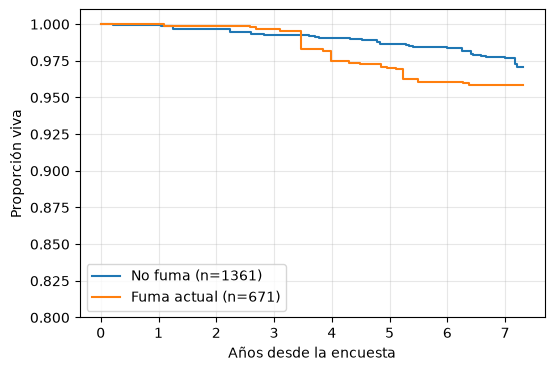

In [14]:
z = d[(d.edad.between(40, 59)) & d.fuma_actual.notna() & (d.w > 0)]
fig, ax = plt.subplots(figsize=(6, 4))
for v, lab in [(0, "No fuma"), (1, "Fuma actual")]:
    s = z[z.fuma_actual == v]
    KaplanMeierFitter().fit(s.t, s.muerto, weights=s.w, label=f"{lab} (n={len(s)})").plot_survival_function(ax=ax, ci_show=False)
ax.set_ylim(0.8, 1.01); ax.set_xlabel("Años desde la encuesta"); ax.set_ylabel("Proporción viva"); ax.grid(alpha=.3)
plt.show()

## 7. De los números a un artículo

### 7.1 Cómo reportar (lista STROBE, versión corta)
- **Diseño y población:** estudio de cohorte con seguimiento por registros, a partir de una encuesta nacional probabilística.
- **Exposición y resultado:** definiciones exactas (ver sección 2) y fecha de cierre del seguimiento (31-12-2023).
- **Estadística:** ponderación, diseño muestral, modelo de Cox, variables de ajuste y análisis de sensibilidad.
- **Resultados:** prevalencias con IC 95%, HR ajustados con IC 95%, **número de muertes por grupo**.
- **Limitaciones:** ver abajo.

### 7.2 Limitaciones que debes declarar
1. **Tabaco medido una sola vez** (al inicio): quien cambió de hábito después queda mal clasificado.
2. **Causalidad inversa y sesgo de supervivencia:** ver el análisis de sensibilidad y las curvas de adultos mayores.
3. **Pocas muertes** en algunos grupos (p. ej. fumadores pasivos) ⇒ sin poder para detectar efectos moderados. *Ausencia de evidencia no es evidencia de ausencia.*
4. **Exposición pasiva autorreportada** y con definición propia, sin biomarcador (cotinina).
5. **Variables de confusión no medidas** (p. ej. nivel socioeconómico, alcohol, comorbilidad).
6. **Causas de muerte:** el registro trae la causa básica en CIE-10; las categorías por causa tienen muy pocos casos.

### 7.3 Escribe tu párrafo de resultados

### ✏️ Ejercicio 9 — Redacta

Con tus números, completa el párrafo (3–5 líneas) como lo escribirías en un *abstract*. Usa tus resultados, no los de un colega.

> **Pista:** Incluye: prevalencia (IC 95%), HR ajustado de fumadores activos (IC 95%), qué encontraste en pasivos **y por qué es prudente no concluir**.

In [15]:
# (Ejemplo de redacción — usa los números de tus resultados)
print("""En la ENS 2016-17 (N = 6.233), la prevalencia de fumadores actuales fue de 32,5% (IC 95% 30,4-34,6) y la de fumadores pasivos
entre quienes no fuman de 25,9% (IC 95% 23,1-28,6). Tras 7 años de seguimiento mediano (539 muertes), los fumadores actuales tuvieron un
riesgo de morir 2,0 veces mayor que quienes nunca fumaron y no estaban expuestos (HR 2,04; IC 95% 1,43-2,90), ajustado por edad y sexo.
No encontramos asociación en fumadores pasivos (HR 0,63; IC 95% 0,35-1,16), pero este grupo tuvo solo 24 muertes, por lo que el estudio carece
de poder para descartar un efecto.""")

En la ENS 2016-17 (N = 6.233), la prevalencia de fumadores actuales fue de 32,5% (IC 95% 30,4-34,6) y la de fumadores pasivos
entre quienes no fuman de 25,9% (IC 95% 23,1-28,6). Tras 7 años de seguimiento mediano (539 muertes), los fumadores actuales tuvieron un
riesgo de morir 2,0 veces mayor que quienes nunca fumaron y no estaban expuestos (HR 2,04; IC 95% 1,43-2,90), ajustado por edad y sexo.
No encontramos asociación en fumadores pasivos (HR 0,63; IC 95% 0,35-1,16), pero este grupo tuvo solo 24 muertes, por lo que el estudio carece
de poder para descartar un efecto.


## 8. Preguntas para discutir en grupo
1. ¿Por qué el HR sin ajustar (< 1) y el ajustado (> 1) apuntan en direcciones opuestas? ¿Qué otras variables podrían confundir?
2. ¿Qué cambiaría si definimos fumador pasivo con otro umbral? ¿Cómo lo probarías?
3. ¿Qué otras preguntas podrías responder con esta base? (por ejemplo: hipertensión, diabetes, obesidad, o la misma pregunta en la ENS 2003 y 2009-10).
4. ¿Qué haría falta para publicar? (comité, protocolo, preregistro del análisis, revisión de limitaciones).

---
**Fuentes:** Ministerio de Salud de Chile, Departamento de Epidemiología. *Encuesta Nacional de Salud 2016-2017*, base de datos y manual de uso. https://epi.minsal.cl/bases-de-datos/